# EDA data sau khi xử lý với LLM model

## Thư viện và Cấu hình

In [22]:
%pip install -q --upgrade matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 150)


# ============================================================
# 2. CONFIGURATION
# ============================================================

DATA_DIR = Path('../data').resolve()
print("DATA_DIR:", DATA_DIR)

# data/raw/legal_qa
RAW_DATA_DIR = DATA_DIR / "raw" 
RAW_QA_DIR = RAW_DATA_DIR / "legal_qa"

# data/processed_legal_qa
PROCESSED_QA_DIR = DATA_DIR / "processed_legal_qa"
DATA_PATH = PROCESSED_QA_DIR / "final_filtered_legal_qa.jsonl"


DATA_DIR: C:\52300070_TMTHUYEN\LEARN_MORE\Apps\datn-legal-ai\backend\data


## Load data


In [24]:
# ============================================================
# 3. LOAD JSONL DATA
# ============================================================

def load_jsonl(path):
    records = []

    with open(path, "r", encoding="utf-8") as f:
        for line_no, line in enumerate(f, start=1):
            if not line.strip():
                continue

            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as e:
                print(f"Invalid JSON at line {line_no}: {e}")

    return pd.DataFrame(records)


df_raw = load_jsonl(DATA_PATH)

# Preserve original loaded data
df_all = df_raw.copy()

print("Dataset shape:", df_all.shape)
print("Number of records:", len(df_all))
print("Number of columns:", len(df_all.columns))

display(df_all.head(3))

# ============================================================
# 4. SCHEMA INSPECTION
# ============================================================

def count_unique_values(series):
    """
    Count unique values, including nested JSON structures.
    """

    def make_hashable(value):
        if value is None:
            return None

        # Convert nested JSON structures to strings
        if isinstance(value, (list, dict)):
            return json.dumps(
                value,
                ensure_ascii=False,
                sort_keys=True,
                default=str
            )

        # Handle scalar missing values
        try:
            if pd.isna(value):
                return None
        except (TypeError, ValueError):
            pass

        return value

    normalized = series.map(make_hashable)

    return normalized.nunique(dropna=True)


# Build schema report
schema = pd.DataFrame({
    "column": df_all.columns,

    "dtype": [
        str(df_all[c].dtype)
        for c in df_all.columns
    ],

    "non_null": [
        df_all[c].notna().sum()
        for c in df_all.columns
    ],

    "null": [
        df_all[c].isna().sum()
        for c in df_all.columns
    ],

    "unique": [
        count_unique_values(df_all[c])
        for c in df_all.columns
    ]
})

display(schema)

Dataset shape: (953, 22)
Number of records: 953
Number of columns: 22


,id,url,source,category,title,question,answer,citation,citation_verified,related_legal_documents,lawyer,listing_page,extraction_status,content_sha256,collected_at_utc,topic,relevant_law,answer_url,source_category_url,processed_answer,relevant_documents,relevant_laws
0,da62d3aa6f234b7d92ee,https://luatvietnam.vn/luat-su-tu-van/quyen-don-phuong-cham-dut-hop-dong-khi-mot-ben-vi-pham-nghia-vu-151927-faqs.html,LuatVietnam,Dân sự,Quyền đơn phương chấm dứt hợp đồng khi một bên vi phạm nghĩa vụ,Xin hỏi LuatVietnam: Tôi là một ca sỹ. Tôi đã ký Hợp đồng hợp tác kinh doanh với một công ty B để công ty B có quyền kinh doanh toàn bộ các bài há...,Trả lời:\n\nTrường hợp của bạn thể hiện Công ty B đã vi phạm nghiêm trọng nghĩa vụ của họ trong hợp đồng hợp tác kinh doanh.\n\nĐiều 428 Bộ luật D...,"[Điều 428 Bộ luật Dân sự 2015 quy định về quyền đơn phương chấm dứt thực hiện hợp đồng khi bên kia vi phạm nghiêm trọng nghĩa v, Điều 428, Điều 15...",False,"[{'title': '', 'url': 'https://luatvietnam.vn/doanh-nghiep/luat-doanh-nghiep-2020-so-59-2020-qh14-186272-d1.html'}, {'title': 'Luật Doanh nghiệp c...",Được tư vấn bởi: Luật sư Hoàng Tuấn Vũ Công ty luật TNHH Tuệ Anh 090 165 9868,1.0,full_qa,c5f3a34ee72751b8da1b8371e72bcbb551b7e128459484856ffe3a4319735cb2,2026-10-28T11:37:33.972299+00:00,Dân sự,None,NaN,NaN,"Công ty B đã vi phạm nghiêm trọng nghĩa vụ hợp đồng do không đối soát và chậm thanh toán doanh thu nhiều tháng, nên bên còn lại có thể đơn phương ...","[Bộ luật Dân sự 2015, Luật Doanh nghiệp 2020]","[{'document_name': 'Bộ luật Dân sự 2015', 'citation': 'Điều 428 Bộ luật Dân sự 2015', 'hierarchy': {'article': '428', 'clause': None, 'point': Non..."
1,91ddd56ddd285f23bba7,https://luatvietnam.vn/luat-su-tu-van/nguoi-khoi-kien-vang-mat-lan-thu-2-thi-co-dinh-chi-giai-quyet-vu-an-dan-su-khong-151598-faqs.html,LuatVietnam,Dân sự,Người khởi kiện vắng mặt lần thứ 2 thì có đình chỉ giải quyết vụ án dân sự không?,Xin hỏi LuatVietnam: Điểm c khoản 1 Điều 217 của Bộ luật Tố tụng dân sự về đình chỉ giải quyết vụ án dân sự quy định: “Người khởi kiện rút toàn bộ...,"Trả lời:\n\nCăn cứ Công văn 163/TANDTC-PC ngày 10/9/2024 của Tòa án nhân dân tối cao quy định như sau:\n\nĐiểm c, khoản 1, Điều 217 của Bộ luật Tố...","[Điều 217 của Bộ luật Tố tụng dân sự quy định, Điều 210 của Bộ luật Tố tụng dân sự quy định]",False,"[{'title': '', 'url': 'https://luatvietnam.vn/tu-phap/cong-van-163-tandtc-pc-cua-toa-an-nhan-dan-toi-cao-ve-viec-giai-dap-mot-so-vuong-mac-trong-x...",Được tư vấn bởi: Luật sư Hoàng Tuấn Vũ Công ty luật TNHH Tuệ Anh 090 165 9868,1.0,full_qa,54ec8f4aeb8761b7c49ec1ac5c0aa33ae84433fdb4619226725bdd19da59642e,2026-10-28T11:37:37.068104+00:00,Dân sự,None,NaN,NaN,"Trong giai đoạn chuẩn bị xét xử sơ thẩm, nếu nguyên đơn đã được triệu tập hợp lệ lần thứ hai để lấy lời khai mà vẫn vắng mặt thì Tòa án đình chỉ g...","[Công văn 163/TANDTC-PC ngày 10/9/2024 của Tòa án nhân dân tối cao, Bộ luật Tố tụng dân sự]","[{'document_name': 'Công văn 163/TANDTC-PC ngày 10/9/2024 của Tòa án nhân dân tối cao', 'citation': 'Công văn 163/TANDTC-PC ngày 10/9/2024 của Tòa..."
2,2e3f08ddd0ff3501e0f1,https://luatvietnam.vn/luat-su-tu-van/nguoi-khoi-kien-vang-mat-lan-thu-2-thi-co-dinh-chi-giai-quyet-vu-an-dan-su-khong-151597-faqs.html,LuatVietnam,Dân sự,Người khởi kiện vắng mặt lần thứ 2 thì có đình chỉ giải quyết vụ án dân sự không?,Xin hỏi LuatVietnam: Điểm c khoản 1 Điều 217 của Bộ luật Tố tụng dân sự về đình chỉ giải quyết vụ án dân sự quy định: “Người khởi kiện rút toàn bộ...,"Trả lời:\n\nCăn cứ Công văn 163/TANDTC-PC ngày 10/9/2024 của Tòa án nhân dân tối cao quy định như sau:\n\nĐiểm c, khoản 1, Điều 217 của Bộ luật Tố...","[Điều 217 của Bộ luật Tố tụng dân sự quy định, Điều 210 của Bộ luật Tố tụng dân sự quy định]",False,[],Được tư vấn bởi: Luật sư Hoàng Tuấn Vũ Công ty luật TNHH Tuệ Anh 090 165 9868,1.0,full_qa,54ec8f4aeb8761b7c49ec1ac5c0aa33ae84433fdb4619226725bdd19da59642e,2026-10-28T11:37:40.334654+00:00,Dân sự,None,NaN,NaN,"Trong giai đoạn chuẩn bị xét xử sơ thẩm

,column,dtype,non_null,null,unique
0,id,str,953,0,953
1,url,str,953,0,953
2,source,str,953,0,3
3,category,str,953,0,2
4,title,str,953,0,951
5,question,str,953,0,945
6,answer,str,953,0,945
7,citation,object,953,0,837
8,citation_verified,object,504,449,1
9,related_legal_documents,object,442,511,212


## Filter data

In [25]:
# ============================================================
# 1. FILTER CONFIGURATION
# ============================================================

FILTER_EMPTY_QUESTION = True
FILTER_EMPTY_ANSWER = True

# None: giữ tất cả category
# {"Dân sự"}: chỉ lấy nhóm dân sự
FOCUS_CATEGORIES = ["Dân sự", "Hôn nhân - Gia đình"]

REMOVE_DUPLICATE_QUESTION = True


# ============================================================
# 2. COPY DATA
# ============================================================

df_filtered = df_all.copy()

initial_count = len(df_filtered)


# ============================================================
# 3. FILTER EMPTY QUESTION
# ============================================================

if FILTER_EMPTY_QUESTION:
    print("Filtering out records with empty questions...")
    df_filtered = df_filtered[
        df_filtered["question"].fillna("").astype(str).str.strip().ne("")
    ]


# ============================================================
# 4. FILTER EMPTY ANSWER
# ============================================================

if FILTER_EMPTY_ANSWER:
    print("Filtering out records with empty answers...")
    df_filtered = df_filtered[
        df_filtered["answer"].fillna("").astype(str).str.strip().ne("")
    ]


# ============================================================
# 5. FILTER LEGAL CATEGORY
# ============================================================

if FOCUS_CATEGORIES is not None:
    print ("Filtering for categories:", FOCUS_CATEGORIES)
    df_filtered = df_filtered[
        df_filtered["category"].isin(FOCUS_CATEGORIES)
    ]


# ============================================================
# 6. OPTIONAL DUPLICATE REMOVAL
# ============================================================

if REMOVE_DUPLICATE_QUESTION:
    print("Removing duplicate questions...")
    df_filtered = df_filtered.drop_duplicates(
        subset=["question"],
        keep="first"
    )

# Map document thành đúng tên

# =========
#  Map document
        
DOCUMENT_NAME_MAPPER = {
    "bộ luật dân sự năm 2015": "Bộ luật Dân sự 2015",
    "bộ luật dân sự 2015": "Bộ luật Dân sự 2015",
    "bộ luật dân sự": "Bộ luật Dân sự",

    "bộ luật tố tụng dân sự năm 2015":
        "Bộ luật Tố tụng dân sự 2015",
    "bộ luật tố tụng dân sự 2015":
        "Bộ luật Tố tụng dân sự 2015",
    "bộ luật tố tụng dân sự":
        "Bộ luật Tố tụng dân sự",

    "bộ luật hình sự năm 2015":
        "Bộ luật Hình sự 2015",
    "bộ luật hình sự 2015":
        "Bộ luật Hình sự 2015",
    "bộ luật hình sự":
        "Bộ luật Hình sự",

    "luật hôn nhân và gia đình năm 2014":
        "Luật Hôn nhân và Gia đình 2014",
    "luật hôn nhân và gia đình 2014":
        "Luật Hôn nhân và Gia đình 2014",
    "luật hôn nhân gia đình năm 2014":
        "Luật Hôn nhân và Gia đình 2014",
    "luật hôn nhân gia đình 2014":
        "Luật Hôn nhân và Gia đình 2014",
}

def normalize_document_name(name):
    if not isinstance(name, str):
        return name

    original = name.strip()

    # normalize khoảng trắng + lowercase để lookup
    key = " ".join(original.split()).lower()

    return DOCUMENT_NAME_MAPPER.get(key, original)

def normalize_relevant_documents(documents):
    if not isinstance(documents, list):
        return documents

    normalized = [
        normalize_document_name(doc)
        for doc in documents
    ]

    # Remove duplicates while preserving order
    return list(dict.fromkeys(normalized))


def normalize_relevant_laws(laws):
    if not isinstance(laws, list):
        return laws

    normalized_laws = []

    for law in laws:
        if not isinstance(law, dict):
            normalized_laws.append(law)
            continue

        # Copy để không mutate object gốc
        law = law.copy()

        law["document_name"] = normalize_document_name(
            law.get("document_name")
        )

        normalized_laws.append(law)

    return normalized_laws


# Apply directly to copied dataframe
if "relevant_documents" in df_filtered.columns:
    df_filtered["relevant_documents"] = (
        df_filtered["relevant_documents"]
        .apply(normalize_relevant_documents)
    )

if "relevant_laws" in df_filtered.columns:
    df_filtered["relevant_laws"] = (
        df_filtered["relevant_laws"]
        .apply(normalize_relevant_laws)
    )
    
    

# ============================================================
# 7. FILTER SUMMARY
# ============================================================

print("Initial records:", initial_count)
print("Records after filtering:", len(df_filtered))
print("Removed records:", initial_count - len(df_filtered))

display(df_filtered.head(3))

Filtering out records with empty questions...
Filtering out records with empty answers...
Filtering for categories: ['Dân sự', 'Hôn nhân - Gia đình']
Removing duplicate questions...
Initial records: 953
Records after filtering: 944
Removed records: 9


,id,url,source,category,title,question,answer,citation,citation_verified,related_legal_documents,lawyer,listing_page,extraction_status,content_sha256,collected_at_utc,topic,relevant_law,answer_url,source_category_url,processed_answer,relevant_documents,relevant_laws
0,da62d3aa6f234b7d92ee,https://luatvietnam.vn/luat-su-tu-van/quyen-don-phuong-cham-dut-hop-dong-khi-mot-ben-vi-pham-nghia-vu-151927-faqs.html,LuatVietnam,Dân sự,Quyền đơn phương chấm dứt hợp đồng khi một bên vi phạm nghĩa vụ,Xin hỏi LuatVietnam: Tôi là một ca sỹ. Tôi đã ký Hợp đồng hợp tác kinh doanh với một công ty B để công ty B có quyền kinh doanh toàn bộ các bài há...,Trả lời:\n\nTrường hợp của bạn thể hiện Công ty B đã vi phạm nghiêm trọng nghĩa vụ của họ trong hợp đồng hợp tác kinh doanh.\n\nĐiều 428 Bộ luật D...,"[Điều 428 Bộ luật Dân sự 2015 quy định về quyền đơn phương chấm dứt thực hiện hợp đồng khi bên kia vi phạm nghiêm trọng nghĩa v, Điều 428, Điều 15...",False,"[{'title': '', 'url': 'https://luatvietnam.vn/doanh-nghiep/luat-doanh-nghiep-2020-so-59-2020-qh14-186272-d1.html'}, {'title': 'Luật Doanh nghiệp c...",Được tư vấn bởi: Luật sư Hoàng Tuấn Vũ Công ty luật TNHH Tuệ Anh 090 165 9868,1.0,full_qa,c5f3a34ee72751b8da1b8371e72bcbb551b7e128459484856ffe3a4319735cb2,2026-10-28T11:37:33.972299+00:00,Dân sự,None,NaN,NaN,"Công ty B đã vi phạm nghiêm trọng nghĩa vụ hợp đồng do không đối soát và chậm thanh toán doanh thu nhiều tháng, nên bên còn lại có thể đơn phương ...","[Bộ luật Dân sự 2015, Luật Doanh nghiệp 2020]","[{'document_name': 'Bộ luật Dân sự 2015', 'citation': 'Điều 428 Bộ luật Dân sự 2015', 'hierarchy': {'article': '428', 'clause': None, 'point': Non..."
1,91ddd56ddd285f23bba7,https://luatvietnam.vn/luat-su-tu-van/nguoi-khoi-kien-vang-mat-lan-thu-2-thi-co-dinh-chi-giai-quyet-vu-an-dan-su-khong-151598-faqs.html,LuatVietnam,Dân sự,Người khởi kiện vắng mặt lần thứ 2 thì có đình chỉ giải quyết vụ án dân sự không?,Xin hỏi LuatVietnam: Điểm c khoản 1 Điều 217 của Bộ luật Tố tụng dân sự về đình chỉ giải quyết vụ án dân sự quy định: “Người khởi kiện rút toàn bộ...,"Trả lời:\n\nCăn cứ Công văn 163/TANDTC-PC ngày 10/9/2024 của Tòa án nhân dân tối cao quy định như sau:\n\nĐiểm c, khoản 1, Điều 217 của Bộ luật Tố...","[Điều 217 của Bộ luật Tố tụng dân sự quy định, Điều 210 của Bộ luật Tố tụng dân sự quy định]",False,"[{'title': '', 'url': 'https://luatvietnam.vn/tu-phap/cong-van-163-tandtc-pc-cua-toa-an-nhan-dan-toi-cao-ve-viec-giai-dap-mot-so-vuong-mac-trong-x...",Được tư vấn bởi: Luật sư Hoàng Tuấn Vũ Công ty luật TNHH Tuệ Anh 090 165 9868,1.0,full_qa,54ec8f4aeb8761b7c49ec1ac5c0aa33ae84433fdb4619226725bdd19da59642e,2026-10-28T11:37:37.068104+00:00,Dân sự,None,NaN,NaN,"Trong giai đoạn chuẩn bị xét xử sơ thẩm, nếu nguyên đơn đã được triệu tập hợp lệ lần thứ hai để lấy lời khai mà vẫn vắng mặt thì Tòa án đình chỉ g...","[Công văn 163/TANDTC-PC ngày 10/9/2024 của Tòa án nhân dân tối cao, Bộ luật Tố tụng dân sự]","[{'document_name': 'Công văn 163/TANDTC-PC ngày 10/9/2024 của Tòa án nhân dân tối cao', 'citation': 'Công văn 163/TANDTC-PC ngày 10/9/2024 của Tòa..."
3,ad0d757cee6eb9c2abbd,https://luatvietnam.vn/luat-su-tu-van/bi-don-yeu-cau-hoan-tra-tien-vay-tra-thua-co-phai-la-yeu-cau-phan-to-151348-faqs.html,LuatVietnam,Dân sự,Bị đơn yêu cầu hoàn trả tiền vay trả thừa có phải là yêu cầu phản tố?,Xin hỏi LuatVietnam: Ông A khởi kiện yêu cầu Ông B (bị đơn) trả tiền vay và lãi vay. Trường hợp có căn cứ xác định bị đơn đã trả tiền lãi nhiều hơ...,Trả lời:\n\nNội dung này được hướng dẫn tại Công văn 250/TANDTC-PC ngày 28/4/2026 về thông báo kết quả giải đáp trực tuyến một số vướng mắc trong ...,[Điều 200 của Bộ luật Tố tụng dân sự quy định],False,"[{'title': '', 'url': 'https://luatvietnam.vn/hanh-chinh/cong-van-250-tandtc-pc-2026-thong-bao-ket-qua-giai-dap-vuong-mac-trong-xet-xu-434015-d6.h...",Được tư vấn bởi: Luật sư Hoàng Tuấn Vũ Công ty luật TNHH Tuệ Anh 090 165 9868,1.0,full_qa,89152401c0a9d12f1219f22169a858b1f5114106bac72fa952b42c676b2d9736,2026-10-28T11:37:4

In [26]:
tests = [
    "Bộ luật Dân sự năm 2015",
    "Bộ luật dân sự năm 2015",
    "Bộ Luật Dân sự năm 2015",
    "Luật Hôn nhân và gia đình năm 2014",
    "Luật Hôn nhân và Gia đình năm 2014",
]

for x in tests:
    print(
        repr(x),
        "->",
        repr(normalize_document_name(x))
    )

'Bộ luật Dân sự năm 2015' -> 'Bộ luật Dân sự 2015'
'Bộ luật dân sự năm 2015' -> 'Bộ luật Dân sự 2015'
'Bộ Luật Dân sự năm 2015' -> 'Bộ luật Dân sự 2015'
'Luật Hôn nhân và gia đình năm 2014' -> 'Luật Hôn nhân và Gia đình 2014'
'Luật Hôn nhân và Gia đình năm 2014' -> 'Luật Hôn nhân và Gia đình 2014'


## EDA data

DATASET OVERVIEW
Number of records: 944
Number of columns: 22
Total memory (MB): 14.14

Columns:
['id', 'url', 'source', 'category', 'title', 'question', 'answer', 'citation', 'citation_verified', 'related_legal_documents', 'lawyer', 'listing_page', 'extraction_status', 'content_sha256', 'collected_at_utc', 'topic', 'relevant_law', 'answer_url', 'source_category_url', 'processed_answer', 'relevant_documents', 'relevant_laws']

MISSING VALUES AND DUPLICATES


,missing_count,missing_percent
source_category_url,931,98.62
answer_url,527,55.83
topic,504,53.39
related_legal_documents,504,53.39
relevant_law,482,51.06
listing_page,462,48.94
citation_verified,449,47.56
collected_at_utc,449,47.56
lawyer,47,4.98
title,0,0.00


question: 0 empty records
answer: 0 empty records
processed_answer: 0 empty records
relevant_documents: 69 empty records
relevant_laws: 88 empty records


duplicate_id                0
duplicate_url               0
duplicate_question          1
duplicate_content_sha256    0
Name: duplicate_count, dtype: int64


TEXT LENGTH STATISTICS


,question_char_length,question_word_length,answer_char_length,answer_word_length,processed_answer_char_length,processed_answer_word_length
count,944.00,944.00,944.00,944.00,944.00,944.00
mean,869.51,196.98,2494.67,557.06,508.79,111.77
std,1000.78,223.40,1339.77,295.18,145.84,32.07
min,81.00,18.00,9.00,2.00,90.00,21.00
25%,357.00,82.00,1613.00,360.75,420.75,92.00
50%,517.00,118.50,2232.50,499.50,507.00,111.00
75%,801.00,183.00,3126.00,699.00,599.25,133.00
max,7017.00,1542.00,10287.00,2293.00,1205.00,273.00


... (13 outputs left out)

,field,present_count,missing_count,coverage_percent
0,article,2570,214,92.31
1,clause,1199,1585,43.07
2,point,222,2562,7.97
3,section,10,2774,0.36
4,subsection,1,2783,0.04
5,part,0,2784,0.00
6,chapter,1,2783,0.04



EXTRACTION QUALITY


missing_document_name       0
missing_citation            0
missing_evidence            0
missing_content          2416
invalid_evidence         2769
invalid_content           361
duplicate_citation          0
Name: count, dtype: int64


Content availability:
Content present (%): 13.22
Evidence present (%): 100.0

EDA VISUALIZATION


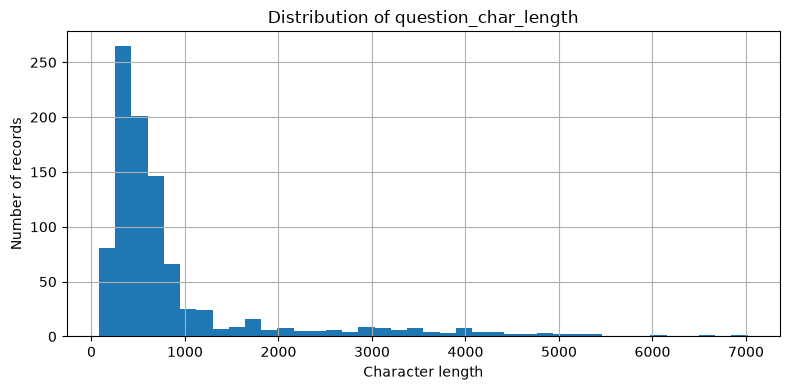

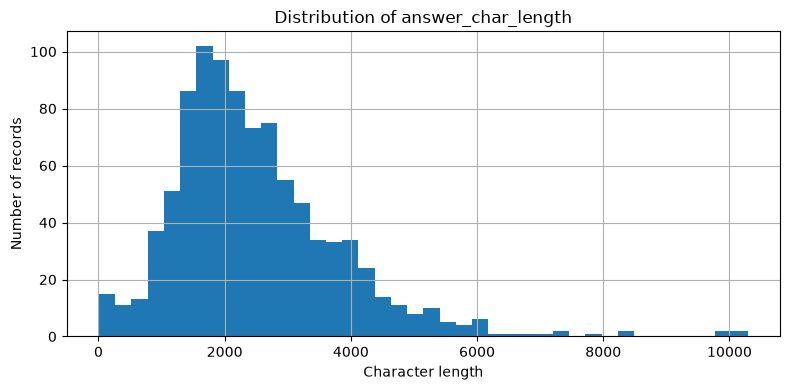

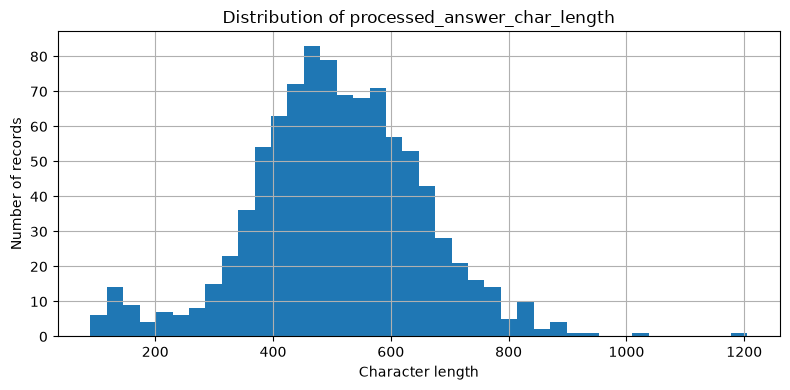

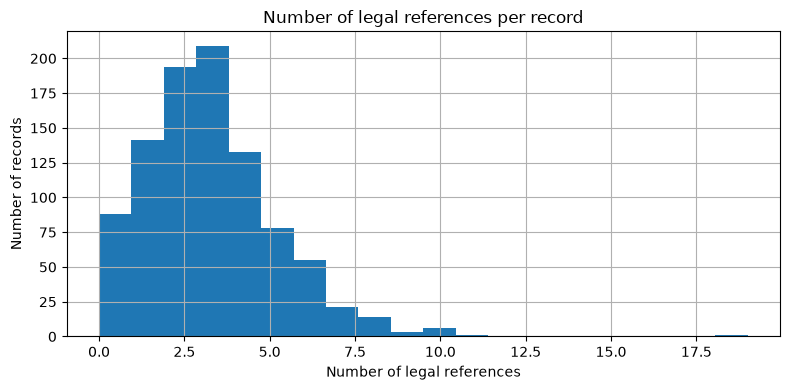

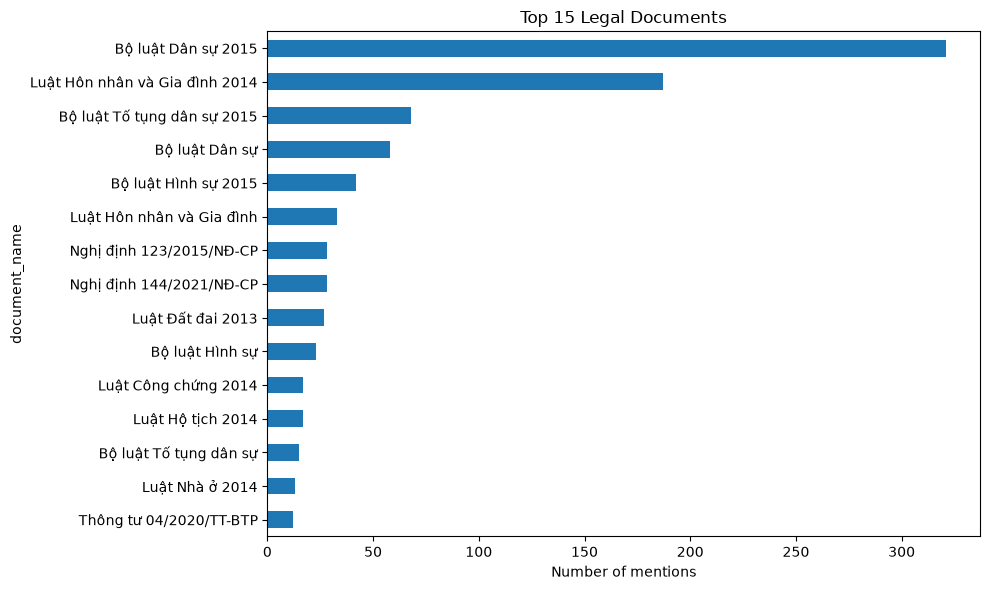


RECORDS FOR MANUAL REVIEW
Records requiring review: 88


,id,question,answer,processed_answer,relevant_documents,relevant_laws
167,ca73536700b7023debdb,"Xin hỏi LuatVietnam: Ông A là chủ sở hữu của bức tranh X – vốn được truyền trong gia đình là tác phẩm của danh họa Y. Tuy nhiên, ông A đã nhận đượ...","Trả lời:\n\nChào bạn, với câu hỏi của bạn, Luật sư có ý kiến tư vấn như sau:\n\nTheo thông tin bạn cung cấp, bức tranh ban đầu thuộc sở hữu của ôn...","Theo nội dung tư vấn, người bán ban đầu đã tự nguyện chuyển nhượng bức tranh và các giao dịch tiếp theo dẫn đến việc bức tranh được tặng cho bảo t...",[],[]
176,135ddad0d1911ad83b63,Xin hỏi LuatVietNbam: Tôi mua xe ô tô được 3 tháng thì bị cháy. Tôi có liên hệ với bên bán để yêu cầu hãng bảo hành vì thời gian bảo hành vẫn còn ...,"Trả lời:\n\nTheo như bạn trình bày, thời gian bảo hành xe ô tô của bạn vẫn còn 2 năm 7 tháng, đồng thời trước đó bạn cũng đã có mua bảo hiểm cháy ...",Việc bồi thường khi ô tô bị cháy phụ thuộc vào nguyên nhân cháy và điều khoản của hợp đồng bảo hiểm. Nếu cháy do lỗi nhà sản xuất và hợp đồng bảo ...,[],[]
183,e69891e42985c4b4fbf9,Xin hỏi LuatVietnam:Gia đình tôi (nguyên đơn) đang vướng vào 1 vụ việc tranh chấp đất đai và chuẩn bị được Toà đưa ra xét xử. Tôi được biết Thẩm p...,"Trả lời:\n\nTrường hợp người tiến hành tố tụng được xác định là không vô tư khi làm nhiệm vụ khi là: vợ, chồng, cha đẻ, mẹ đẻ, cha nuôi, mẹ nuôi, ...","Người tiến hành tố tụng phải từ chối hoặc bị thay đổi khi có căn cứ cho thấy họ có thể không vô tư khi thực hiện nhiệm vụ, không chỉ trong quan hệ...",[],[]
327,63e9a1aa6fd61b62fae1,"Em 22 tuổi đã lấy vợ có con, em là kinh tế chính của gia đình. Em làm nghề tự do nên không có chứng minh thu nhập hay hợp đồng lao động gì. Làm cá...",Trả lời:\n\n- Chưa đủ sức khỏe phục vụ tại ngũ theo kết luận của Hội đồng khám sức khỏe.\n\n- Là lao động duy nhất phải trực tiếp nuôi dưỡng thân ...,"Theo câu trả lời, “lao động chính trong gia đình” không tự động thuộc trường hợp được tạm hoãn nghĩa vụ quân sự. Căn cứ được mô tả yêu cầu phải là...",[],[]
414,e95dbeec706cd4ce9473,"Xin hỏi LuatVietnam: Tôi đang muốn thay đổi giấy khai sinh của con tôi theo họ cha. Trước đó tôi và vợ tôi không làm thủ tục đăng ký kết hôn, vì v...",Trả lời:\n\nVới từng Trung tâm xét nghiệm ADN cha con sẽ có từng yêu cầu khác nhau. Kết quả của các Trung tâm xét nghiệm ADN được cấp phép hợp ph...,"Kết quả xét nghiệm ADN do cơ sở xét nghiệm được cấp phép hợp pháp có thể được sử dụng làm bằng chứng về quan hệ cha, con theo nội dung tư vấn. Quy...",[],[]
436,7210cc6627b36995bdfd,Tôi đã làm xong thủ tục ly hôn với chồng. Bây giờ tôi muốn cắt khẩu ra khỏi sổ hộ khẩu của nhà chồng thì cần những giấy tờ thủ tục gì và bước đầu ...,"Trả lời:\n\nChào bạn. Từ ngày 01/7/2021, khi Luật Cư trú 2020 có hiệu lực, đã không cò tồn tại thủ tục cắt hộ khẩu (hay xin giấy chuyển hộ khẩu) n...","Từ khi Luật Cư trú 2020 có hiệu lực, câu trả lời cho biết không còn thủ tục cắt hộ khẩu hoặc xin giấy chuyển hộ khẩu. Hồ sơ đăng ký thường trú phụ...",[Luật Cư trú 2020],[]
440,9397bab2b0bc5848cc24,Căn nhà hiện tại em đang ở do cha và mẹ em đồng đứng tên và chỉ có 03 người trong hộ khẩu. Tiền mua nhà đất được phía nội cho cha em vào năm 2000 ...,"Trả lời:\n\nTheo thông tin bạn cung cấp, căn nhà này đứng tên bố mẹ bạn, căn cứ quy định pháp luật, căn nhà này được coi là tài sản chung của bố m...","Phần tài sản thuộc sở hữu của người cha khi chết trở thành di sản. Nếu không có di chúc, di sản được chia theo pháp luật cho những người thuộc hàn...",[],[]
446,vne_5124102,"Năm 2025, sau khi ký hợp đồng cho thuê nhà 120 triệu đồng/tháng trong 5 năm, tôi đã thực hiện thủ tục kê khai và nộp thuế thu nhập cá nhân, thuế g...","Theo quy định của pháp luật, trường hợp khách thuê nhà chưa thanh toán tiền thuê không được phép hiểu là người cho thuê đương nhiên không phải kê ...",Việc bên thuê chưa thanh toán tiền không đồng nghĩa người cho thuê đương nhiên không phải kê khai hoặc nộp thuế. Người cho thuê cần rà soát hợp đồ...,[Nghị định 68/2026/NĐ-CP],[]
452,vne_5102664,"Tôi 

In [27]:
# ============================================================
# 1. HELPER FUNCTIONS
# ============================================================
from src.utils.file_utils import FileUtils

def safe_list(value):
    return value if isinstance(value, list) else []


def safe_text(value):
    if value is None or pd.isna(value):
        return ""
    return str(value)


def normalize_text(value):
    return re.sub(r"\s+", " ", safe_text(value)).strip()




# ============================================================
# 2. DATASET OVERVIEW
# ============================================================

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print("Number of records:", len(df_filtered))
print("Number of columns:", len(df_filtered.columns))
print("Total memory (MB):", round(
    df_filtered.memory_usage(deep=True).sum() / 1024**2, 2
))

print("\nColumns:")
print(df_filtered.columns.tolist())



# ============================================================
# 3. MISSING VALUES AND DUPLICATES
# ============================================================

print("\n" + "=" * 60)
print("MISSING VALUES AND DUPLICATES")
print("=" * 60)

missing_stats = pd.DataFrame({
    "missing_count": df_filtered.isna().sum(),
    "missing_percent": (
        df_filtered.isna().mean() * 100
    ).round(2)
})

display(missing_stats.sort_values(
    "missing_percent", ascending=False
))

# Empty string statistics for important fields
important_fields = [
    "question",
    "answer",
    "processed_answer",
    "relevant_documents",
    "relevant_laws"
]

for col in important_fields:
    if col not in df_filtered.columns:
        continue

    if col in ["relevant_documents", "relevant_laws"]:
        empty_count = df_filtered[col].apply(
            lambda x: len(safe_list(x)) == 0
        ).sum()
    else:
        empty_count = df_filtered[col].apply(
            lambda x: normalize_text(x) == ""
        ).sum()

    print(f"{col}: {empty_count} empty records")

# Duplicate statistics
duplicate_stats = {
    "duplicate_id": (
        df_filtered["id"].duplicated().sum()
        if "id" in df_filtered else None
    ),
    "duplicate_url": (
        df_filtered["url"].duplicated().sum()
        if "url" in df_filtered else None
    ),
    "duplicate_question": (
        df_filtered["question"].apply(
            lambda x: normalize_text(x).lower()
        ).duplicated().sum()
    ),
    "duplicate_content_sha256": (
        df_filtered["content_sha256"].duplicated().sum()
        if "content_sha256" in df_filtered else None
    )
}

display(pd.Series(duplicate_stats, name="duplicate_count"))


# ============================================================
# 4. TEXT LENGTH STATISTICS
# ============================================================

print("\n" + "=" * 60)
print("TEXT LENGTH STATISTICS")
print("=" * 60)

text_fields = [
    "question",
    "answer",
    "processed_answer"
]

for col in text_fields:
    if col not in df_filtered.columns:
        continue

    df_filtered[f"{col}_char_length"] = (
        df_filtered[col].apply(
            lambda x: len(safe_text(x))
        )
    )

    df_filtered[f"{col}_word_length"] = (
        df_filtered[col].apply(
            lambda x: len(safe_text(x).split())
        )
    )

length_columns = [
    f"{col}_{unit}_length"
    for col in text_fields
    for unit in ["char", "word"]
    if f"{col}_{unit}_length" in df_filtered.columns
]

display(df_filtered[length_columns].describe().round(2))

# Compare RAW answer and processed answer
comparison = pd.DataFrame({
    "answer_length": df_filtered["answer"].apply(
        lambda x: len(safe_text(x))
    ),
    "processed_answer_length": df_filtered["processed_answer"].apply(
        lambda x: len(safe_text(x))
    )
})

comparison["compression_ratio"] = np.where(
    comparison["answer_length"] > 0,
    comparison["processed_answer_length"]
    / comparison["answer_length"],
    np.nan
)

print("\nAnswer compression statistics:")
display(comparison["compression_ratio"].describe().round(3))


# ============================================================
# 5. DATASET DISTRIBUTION
# ============================================================

print("\n" + "=" * 60)
print("DATASET DISTRIBUTION")
print("=" * 60)

for col in ["source", "category", "topic", "extraction_status"]:
    if col not in df_filtered.columns:
        continue

    print(f"\nTop values: {col}")

    display(
        df_filtered[col]
        .fillna("UNKNOWN")
        .value_counts()
        .head(20)
        .rename_axis(col)
        .reset_index(name="count")
    )


# ============================================================
# 6. LEGAL DOCUMENT AND CITATION ANALYSIS
# ============================================================

print("\n" + "=" * 60)
print("LEGAL DOCUMENT AND CITATION ANALYSIS")
print("=" * 60)

law_records = []
document_records = []


for row_idx, row in df_filtered.reset_index(drop=True).iterrows():

    # Relevant documents
    for doc in safe_list(row.get("relevant_documents")):
        
        if isinstance(doc, str):
            document_records.append({
                "row_index": row_idx,
                "document_name": doc
            })

    # Relevant laws
    for law in safe_list(row.get("relevant_laws")):
        if not isinstance(law, dict):
            continue

        hierarchy = law.get("hierarchy")
        if not isinstance(hierarchy, dict):
            hierarchy = {}

        law_records.append({
            "row_index": row_idx,
            "document_name": law.get("document_name"),
            "citation": law.get("citation"),
            "article": hierarchy.get("article"),
            "clause": hierarchy.get("clause"),
            "point": hierarchy.get("point"),
            "section": hierarchy.get("section"),
            "subsection": hierarchy.get("subsection"),
            "part": hierarchy.get("part"),
            "chapter": hierarchy.get("chapter"),
            "content": law.get("content"),
            "evidence": law.get("evidence_in_raw_answer")
        })

df_laws = pd.DataFrame(law_records)
df_documents = pd.DataFrame(document_records)

print("Total law objects:", len(df_laws))
print("Total document mentions:", len(df_documents))

print(
    "Records containing laws:",
    df_filtered["relevant_laws"].apply(
        lambda x: len(safe_list(x)) > 0
    ).sum()
)

# Document frequency
if not df_documents.empty:
    # print all documents
    print("\nAll legal documents:")
    print(
        df_documents["document_name"].to_list()
    )
    
    
    print("\nTop 20 legal documents:")

    display(
        df_documents["document_name"]
        .value_counts()
        .head(500)
        .rename_axis("document_name")
        .reset_index(name="count")
    )
    
# mapper documents trong filterd data
print("Mapper doucument names in df_laws...")
for idx, row in df_laws.iterrows():
    original_name = row["document_name"]
    normalized_name = normalize_document_name(original_name)
    df_laws.at[idx, "document_name"] = normalized_name

# Citation hierarchy coverage
if not df_laws.empty:

    hierarchy_fields = [
        "article",
        "clause",
        "point",
        "section",
        "subsection",
        "part",
        "chapter"
    ]

    hierarchy_stats = pd.DataFrame({
        "field": hierarchy_fields,
        "present_count": [
            df_laws[col].apply(
                lambda x: normalize_text(x) != ""
            ).sum()
            for col in hierarchy_fields
        ]
    })

    hierarchy_stats["missing_count"] = (
        len(df_laws) - hierarchy_stats["present_count"]
    )

    hierarchy_stats["coverage_percent"] = (
        hierarchy_stats["present_count"] / len(df_laws) * 100
    ).round(2)

    display(hierarchy_stats)


# ============================================================
# 7. EXTRACTION QUALITY ANALYSIS
# ============================================================

print("\n" + "=" * 60)
print("EXTRACTION QUALITY")
print("=" * 60)

if not df_laws.empty:

    def contains_in_raw(value, raw):
        value = normalize_text(value)
        raw = normalize_text(raw)

        return bool(value) and value in raw

    raw_answers = df_filtered["answer"].apply(
        normalize_text
    ).to_dict()

    df_laws["evidence_valid"] = df_laws.apply(
        lambda r: contains_in_raw(
            r["evidence"],
            raw_answers.get(r["row_index"], "")
        ),
        axis=1
    )

    df_laws["content_valid"] = df_laws.apply(
        lambda r: (
            True if pd.isna(r["content"]) or r["content"] is None
            else contains_in_raw(
                r["content"],
                raw_answers.get(r["row_index"], "")
            )
        ),
        axis=1
    )

    quality_stats = {
        "missing_document_name": df_laws["document_name"].isna().sum(),
        "missing_citation": df_laws["citation"].isna().sum(),
        "missing_evidence": df_laws["evidence"].isna().sum(),
        "missing_content": df_laws["content"].isna().sum(),
        "invalid_evidence": (~df_laws["evidence_valid"]).sum(),
        "invalid_content": (~df_laws["content_valid"]).sum(),
        "duplicate_citation": df_laws.duplicated(
            subset=["row_index", "citation"]
        ).sum()
    }

    display(pd.Series(quality_stats, name="count"))

    # Content and evidence coverage
    print("\nContent availability:")
    print(
        "Content present (%):",
        round(df_laws["content"].notna().mean() * 100, 2)
    )

    print(
        "Evidence present (%):",
        round(df_laws["evidence"].notna().mean() * 100, 2)
    )


# ============================================================
# 8. VISUALIZATION
# ============================================================

print("\n" + "=" * 60)
print("EDA VISUALIZATION")
print("=" * 60)

# Text length distribution
for col in [
    "question_char_length",
    "answer_char_length",
    "processed_answer_char_length"
]:
    if col not in df_filtered.columns:
        continue

    plt.figure(figsize=(8, 4))
    df_filtered[col].hist(bins=40)
    plt.title(f"Distribution of {col}")
    plt.xlabel("Character length")
    plt.ylabel("Number of records")
    plt.tight_layout()
    plt.show()


# Number of laws per record
law_counts = df_filtered["relevant_laws"].apply(
    lambda x: len(safe_list(x))
)

plt.figure(figsize=(8, 4))
law_counts.hist(bins=20)
plt.title("Number of legal references per record")
plt.xlabel("Number of legal references")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()


# Top legal documents
if not df_documents.empty:
    plt.figure(figsize=(10, 6))

    df_documents["document_name"].value_counts().head(15).sort_values().plot(
        kind="barh"
    )

    plt.title("Top 15 Legal Documents")
    plt.xlabel("Number of mentions")
    plt.tight_layout()
    plt.show()


# ============================================================
# 9. RECORDS FOR MANUAL REVIEW
# ============================================================

print("\n" + "=" * 60)
print("RECORDS FOR MANUAL REVIEW")
print("=" * 60)

review_mask = (
    df_filtered["question"].fillna("").astype(str).str.strip().eq("")
    | df_filtered["answer"].fillna("").astype(str).str.strip().eq("")
    | df_filtered["processed_answer"].fillna("").astype(str).str.strip().eq("")
    | df_filtered["relevant_laws"].apply(
        lambda x: len(safe_list(x)) == 0
    )
)

df_review = df_filtered.loc[
    review_mask,
    [
        c for c in [
            "id", "question", "answer", "processed_answer",
            "relevant_documents", "relevant_laws"
        ]
        if c in df_filtered.columns
    ]
].copy()

print("Records requiring review:", len(df_review))

display(df_review.head(20))